# Projet Leyenda — Deliverable 3: Image captioning

**Client:** TouNum (document digitization) · **Team:** CESI Data Science

This is the last block of the Leyenda pipeline. Deliverable 1 sorts the images and keeps only the photos, Deliverable 2 removes their noise, and here we generate a **caption** for each photo.

The network is trained on **MS COCO**, a dataset of photos where each image has about 5 captions written by people. It has two parts: a **CNN** that encodes the image into a compact representation, and an **RNN** that uses this representation to write the caption word by word. Before the training, all the images go through **InceptionV3**, a CNN already trained for classification.

**Contents**

1. Architecture of the network
2. Data and pre-processing (images and text)
3. The CNN and RNN models
4. Training and loss curve
5. Test: captions of test images
6. Improving the model
7. The complete workflow: from an unidentified image to a captioned photo

# 1. Architecture of the network

```
 image (299×299×3)
      │
      ▼
 InceptionV3, pre-trained on ImageNet (frozen, without its classification layers)
      │  last convolutional block: 8×8×2048  →  reshaped to 64×2048 and saved on disk (.npy)
      ▼
 CNN ENCODER: Dense(256) + ReLU  →  64×256  (one vector per image region)
      │
      ▼                                  repeated for each word of the caption
 ┌──────────────────────────────────────────────────────────────────────────────────┐
 │ ATTENTION (Bahdanau)                                                             │
 │   Dense(512)(regions) + Dense(512)(GRU state) → tanh → Dense(1) → softmax        │
 │   → 64 attention weights → context vector (256) = weighted sum of the regions    │
 │                                                                                  │
 │ RNN DECODER                                                                      │
 │   previous word → Embedding(5001 → 256) ─┐                                       │
 │   context vector (256) ──────────────────┴→ concatenation (512)                  │
 │   → GRU (512 cells) → Dense(512) → Dense(5001) → score of each word → next word  │
 └──────────────────────────────────────────────────────────────────────────────────┘
```

**The CNN used for pre-processing: InceptionV3.** It is a deep CNN (about 21.8 million parameters without its classification layers) trained on ImageNet, 1.2 million images in 1,000 classes. Its *Inception modules* apply convolutions of several sizes (1×1, 3×3, 5×5) in parallel, so it detects patterns at several scales. We remove its classification layers and keep the output of its last convolutional block: an 8×8 grid of 2,048 features. We do not train it again (transfer learning): its features already describe the content of an image well, and they save us from training a huge CNN ourselves.

**Layers of our network**

| Part | Layer | Size (cells) | Type | Role |
|---|---|---|---|---|
| Pre-processing | InceptionV3 | output 8×8×2048 | pre-trained CNN, frozen | turns the image into 64 regions × 2,048 features, saved on disk |
| CNN encoder | `Dense(256)` + ReLU | 256 | fully connected | compresses the 2,048 features of each region into 256, keeping the 64 regions separate |
| Attention | `W1 = Dense(512)` | 512 | fully connected | projects the 64 regions |
| | `W2 = Dense(512)` | 512 | fully connected | projects the hidden state of the GRU (what was already written) |
| | `V = Dense(1)` + softmax | 1 | fully connected | gives one weight per region: where to look for the next word |
| RNN decoder | `Embedding` | 5,001 words → 256 | embedding | turns the index of the previous word into a vector |
| | `GRU` | 512 cells, 1 layer | recurrent | memory of the sentence; takes the word + the context vector |
| | `Dense(512)` | 512 | fully connected | intermediate layer after the GRU |
| | `Dense(5001)` | 5,001 | fully connected | one score per word of the vocabulary: the next word is chosen from these scores |

In total, the encoder and the decoder have about 6.6 million weights to train (2.6 million of them in the last layer, because it has one output per word of the vocabulary).

# 2. Data and pre-processing

### Libraries

In [1]:
import tensorflow as tf

# The GPU memory is taken as needed instead of all at once (the training process of 6.5 also needs some)
for gpu in tf.config.list_physical_devices('GPU'):
    tf.config.experimental.set_memory_growth(gpu, True)

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.utils import shuffle

import collections
import random
import re
import numpy as np
import os
import time
import json
import math
import textwrap
import urllib.request
from glob import glob
from PIL import Image
import pickle
from tqdm import tqdm

I0000 00:00:1793695089.478636   12650 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793695093.529130   12650 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793695106.948726   12650 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


### Loading the MS COCO data

The captions are in `captions_train2014.json`. For each image we group its captions (about 5 per image) and mark the beginning and the end of each one with `<start>` and `<end>`, so that the network knows where a sentence starts and when to stop. We keep the first 2,000 images, which gives about 10,000 captions: training on the 82,000 images of COCO would take far too long on a CPU.

In [2]:
def local_path(windows_path):
    # The notebook runs on Windows or on Ubuntu (WSL, to use the GPU): under Linux, C:\... becomes /mnt/c/...
    if os.name == "nt":
        return windows_path
    return "/mnt/" + windows_path[0].lower() + windows_path[2:].replace("\\", "/")

# Folder containing "annotations" and "train2014" (MS COCO 2014)
COCO_DIR = local_path(r"D:\COCO")

# Folder of the InceptionV3 features (.npy). Under Linux they go on the Linux disk:
# reading them from the Windows disk is about 200 times slower from WSL
FEATURES_DIR = os.path.join(COCO_DIR, "train2014") if os.name == "nt" else os.path.expanduser("~/coco_features")
os.makedirs(FEATURES_DIR, exist_ok=True)

def feature_path(image_path):
    # Path of the .npy file holding the InceptionV3 features of an image
    return os.path.join(FEATURES_DIR, os.path.basename(image_path) + ".npy")
NUM_IMAGES = 2000

# Annotation file path
annotation_file = os.path.join(COCO_DIR, "annotations", "captions_train2014.json")

# Path to folder containing images to be annotated
PATH = os.path.join(COCO_DIR, "train2014") + os.sep

# Read annotation file
with open(annotation_file, 'r') as f:
    annotations = json.load(f)

# Group all annotations with the same identifier
image_path_to_caption = collections.defaultdict(list)
for val in annotations['annotations']:
    # mark the beginning and end of each annotation
    caption = f"<start> {val['caption']} <end>"
    # the image ID is part of the image path
    image_path = PATH + 'COCO_train2014_' + '%012d.jpg' % (val['image_id'])
    image_path_to_caption[image_path].append(caption)

# Take the first images only
image_paths = list(image_path_to_caption.keys())
train_image_paths = image_paths[:NUM_IMAGES]

# List of all the captions, and of the image of each caption (an image is repeated once per caption)
train_captions = []
img_name_vector = []
for image_path in train_image_paths:
    caption_list = image_path_to_caption[image_path]
    train_captions.extend(caption_list)
    img_name_vector.extend([image_path] * len(caption_list))

print(len(train_image_paths), "images,", len(train_captions), "captions")
print("Example:", train_captions[0])

2000 images, 10005 captions
Example: <start> A very clean and well decorated empty bathroom <end>


### Image pre-processing with InceptionV3

Each image is resized to 299×299 (the input size of InceptionV3) and its pixels are normalised between -1 and 1, as InceptionV3 expects. It then goes through InceptionV3 without its classification layers, which gives an 8×8×2048 block, reshaped into **64×2048**: 64 regions of the image, each described by 2,048 features.

These features are computed **only once** and saved on disk (one `.npy` file per image, in `FEATURES_DIR`: next to the images on Windows, on the Linux disk when the notebook runs on Ubuntu with the GPU). During the training we load these compact representations instead of the images: it is much faster, and we never need to keep thousands of images in memory.

Before that, we check the images: a missing or damaged one is downloaded again from the COCO website, and if it is still unreadable it is removed with its captions.

In [3]:
# InceptionV3 pre-trained on ImageNet, without its classification layers
image_model = tf.keras.applications.InceptionV3(include_top=False, weights='imagenet')
new_input = image_model.input
hidden_layer = image_model.layers[-1].output          # last convolutional block: 8x8x2048

# Model that computes the compact representation of an image
image_features_extract_model = tf.keras.Model(new_input, hidden_layer)

def load_image(image_path):
    """Reads an image, decodes it in RGB, resizes it to 299x299 and normalises it to [-1, 1]."""
    img = tf.io.read_file(image_path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, (299, 299))
    img = tf.keras.applications.inception_v3.preprocess_input(img)
    return img, image_path

# --- Check the images before using them ---------------------------------------
def image_ok(p):
    """True if the file exists and TensorFlow can decode it entirely."""
    try:
        tf.image.decode_jpeg(tf.io.read_file(p), channels=3)
        return True
    except Exception:
        return False

def download_image(p):
    """Downloads to a temporary file first, so an interruption never leaves a half image."""
    tmp = p + '.part'
    urllib.request.urlretrieve('http://images.cocodataset.org/train2014/' + os.path.basename(p), tmp)
    os.replace(tmp, p)

os.makedirs(PATH, exist_ok=True)
encode_train = sorted(set(img_name_vector))
bad = [p for p in tqdm(encode_train, desc='checking') if not os.path.exists(p) or not image_ok(p)]
print(len(encode_train), "images expected |", len(bad), "missing or damaged")
for p in tqdm(bad, desc='downloading'):
    download_image(p)

# Images still unreadable after a new download are removed (with their captions)
still_bad = set(p for p in bad if not image_ok(p))
if still_bad:
    print(len(still_bad), "unreadable image(s) removed:", sorted(still_bad)[:3])
    keep = [p not in still_bad for p in img_name_vector]
    train_captions = [c for c, k in zip(train_captions, keep) if k]
    img_name_vector = [p for p, k in zip(img_name_vector, keep) if k]

# --- Compute the features once and save them on disk ---------------------------
encode_train = sorted(set(img_name_vector))
image_dataset = tf.data.Dataset.from_tensor_slices(encode_train)
image_dataset = image_dataset.map(load_image, num_parallel_calls=tf.data.AUTOTUNE).batch(16)

for img, path in tqdm(image_dataset, desc='InceptionV3'):
    batch_features = image_features_extract_model(img)                        # (16, 8, 8, 2048)
    batch_features = tf.reshape(batch_features,
                                (batch_features.shape[0], -1, batch_features.shape[3]))   # (16, 64, 2048)
    for bf, p in zip(batch_features, path):
        np.save(feature_path(p.numpy().decode("utf-8")), bf.numpy())         # saved as <image>.jpg.npy

I0000 00:00:1793695131.718438   12650 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5560 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4060 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9
checking: 100%|██████████| 2000/2000 [00:58<00:00, 34.24it/s]


2000 images expected | 0 missing or damaged


downloading: 0it [00:00, ?it/s]
InceptionV3:   0%|          | 0/125 [00:00<?, ?it/s]I0000 00:00:1793695197.287942   12650 cuda_dnn.cc:461] Loaded cuDNN version 92700
W0000 00:00:1793695204.383541   12650 bfc_allocator.cc:383] Garbage collection: deallocate free memory regions (i.e., allocations) so that we can re-allocate a larger region to avoid OOM due to memory fragmentation. If you see this message frequently, you are running near the threshold of the available device memory and re-allocation may incur great performance overhead. You may try smaller batch sizes to observe the performance impact. Set TF_ENABLE_GPU_GARBAGE_COLLECTION=false if you'd like to disable this feature.
InceptionV3: 100%|██████████| 125/125 [01:02<00:00,  2.01it/s]


### Text pre-processing

A neural network cannot read words, so the captions are turned into sequences of numbers:

1. **splitting into words**: the punctuation and special characters are removed and the sentences are cut into words;
2. **vocabulary**: we keep the **5,000 most frequent words**; the rarer ones become `<unk>` (unknown word);
3. **indexes**: each word is replaced by its number in the vocabulary;
4. **padding**: all the sequences are filled with `<pad>` (index 0) up to the length of the longest caption, so that they all have the same size.

In [4]:
# Maximum length of a caption
def calc_max_length(tensor):
    return max(len(t) for t in tensor)

# Keep the 5000 most frequent words of the vocabulary
top_k = 5000
tokenizer = tf.keras.preprocessing.text.Tokenizer(num_words=top_k,
                                                  oov_token="<unk>",
                                                  filters=r'!"#$%&()*+.,-/:;=?@[\]^_`{|}~ ')
tokenizer.fit_on_texts(train_captions)

# Token used to fill the captions up to the same length
tokenizer.word_index['<pad>'] = 0
tokenizer.index_word[0] = '<pad>'

# Captions (lists of words) -> sequences of word indexes
train_seqs = tokenizer.texts_to_sequences(train_captions)

# Fill each sequence up to the length of the longest caption
cap_vector = tf.keras.preprocessing.sequence.pad_sequences(train_seqs, padding='post')

# Maximum length, used later to store the attention weights
max_length = calc_max_length(train_seqs)

print("Caption:", train_captions[0])
print("Indexes:", cap_vector[0])
print("Maximum length:", max_length, "words")

Caption: <start> A very clean and well decorated empty bathroom <end>
Indexes: [  3   2  87  76   6 301 191 124  11   4   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
Maximum length: 33 words


### Training set and test set

The split is done **by image** (80 % / 20 %), not by caption: all the captions of an image go in the same set, so the test images are really new for the network. The shuffle uses a fixed seed, so the split is the same at every run (otherwise a training resumed from a checkpoint could have seen some of the test photos).

In [5]:
# Dictionary: image -> list of its captions (as index sequences)
img_to_cap_vector = collections.defaultdict(list)
for img, cap in zip(img_name_vector, cap_vector):
    img_to_cap_vector[img].append(cap)

# 80-20 split on the images
img_keys = list(img_to_cap_vector.keys())
random.Random(42).shuffle(img_keys)          # fixed seed: the same split at every run
slice_index = int(len(img_keys) * 0.8)
img_name_train_keys, img_name_val_keys = img_keys[:slice_index], img_keys[slice_index:]

# Training set: one entry per (image, caption) pair
img_name_train = []
cap_train = []
for imgt in img_name_train_keys:
    capt_len = len(img_to_cap_vector[imgt])
    img_name_train.extend([imgt] * capt_len)
    cap_train.extend(img_to_cap_vector[imgt])

# Test set
img_name_val = []
cap_val = []
for imgv in img_name_val_keys:
    capv_len = len(img_to_cap_vector[imgv])
    img_name_val.extend([imgv] * capv_len)
    cap_val.extend(img_to_cap_vector[imgv])

len(img_name_train), len(cap_train), len(img_name_val), len(cap_val)

(8004, 8004, 2001, 2001)

The training data is given to the network with a `tf.data.Dataset`: for each pair, the InceptionV3 features are loaded from their `.npy` file, then the pairs are shuffled and grouped in batches of 64.

In [6]:
BATCH_SIZE = 64          # batch size
BUFFER_SIZE = 1000       # buffer size for shuffling
embedding_dim = 256      # size of the word vectors and of the encoder output
units = 512              # number of cells of the GRU
vocab_size = top_k + 1
num_steps = len(img_name_train) // BATCH_SIZE

# Shape of the InceptionV3 features: 64 regions x 2048 features
features_shape = 2048
attention_features_shape = 64

# Loads the features of an image from its .npy file
def map_func(img_name, cap):
    img_tensor = np.load(feature_path(img_name.decode('utf-8')))
    return img_tensor, cap

dataset = tf.data.Dataset.from_tensor_slices((img_name_train, cap_train))
dataset = dataset.map(lambda item1, item2: tf.numpy_function(
                          map_func, [item1, item2], [tf.float32, tf.int32]),
                      num_parallel_calls=tf.data.AUTOTUNE)
dataset = dataset.shuffle(BUFFER_SIZE).batch(BATCH_SIZE)
dataset = dataset.prefetch(buffer_size=tf.data.AUTOTUNE)

# 3. The CNN and RNN models

### The CNN encoder

The images are already encoded by InceptionV3, so the encoder is small: a single dense layer of 256 neurons with a ReLU, applied to each of the 64 regions. We do **not** flatten the 64×2048 block: by keeping the 64 regions separate, we keep the information about *where* things are in the image, which the attention mechanism needs.

In [7]:
class CNN_Encoder(tf.keras.Model):
    # The images are already pre-processed by InceptionV3:
    # the encoder only passes their features through a dense layer
    def __init__(self, embedding_dim):
        super(CNN_Encoder, self).__init__()
        # shape after fc == (batch_size, 64, embedding_dim)
        self.fc = tf.keras.layers.Dense(embedding_dim)

    def call(self, x):
        x = self.fc(x)
        x = tf.nn.relu(x)
        return x

### The attention mechanism

For each word to predict, the attention decides **which regions of the image to look at**. It takes the 64 regions given by the encoder and the hidden state of the GRU (a summary of the words already written), passes both through a dense layer of 512 neurons, adds them and applies a `tanh`. A last dense layer gives a score to each region, and a softmax turns the 64 scores into **attention weights** that sum to 1. The **context vector** is the sum of the regions weighted by these weights: it mostly contains the information of the important regions.

In [8]:
class BahdanauAttention(tf.keras.Model):
    def __init__(self, units):
        super(BahdanauAttention, self).__init__()
        self.W1 = tf.keras.layers.Dense(units)
        self.W2 = tf.keras.layers.Dense(units)
        self.V = tf.keras.layers.Dense(1)

    def call(self, features, hidden):
        # features (output of the CNN encoder) shape == (batch_size, 64, embedding_dim)
        # hidden shape == (batch_size, units)
        hidden_with_time_axis = tf.expand_dims(hidden, 1)

        attention_hidden_layer = tf.nn.tanh(self.W1(features) + self.W2(hidden_with_time_axis))

        # One score per region of the image
        score = self.V(attention_hidden_layer)

        # Scores -> attention weights (they sum to 1 over the 64 regions)
        attention_weights = tf.nn.softmax(score, axis=1)

        # Context vector: weighted sum of the regions
        context_vector = attention_weights * features
        context_vector = tf.reduce_sum(context_vector, axis=1)

        return context_vector, attention_weights

### The RNN decoder

The decoder writes the caption **one word at a time**. At each step it receives the previous word, the image features and the hidden state of the GRU:

1. the attention computes the context vector of the image;
2. the previous word goes through an **Embedding** layer, which turns its index into a vector of 256 values;
3. this vector is concatenated with the context vector and given to the **GRU** (512 cells), whose hidden state is the memory of the sentence so far;
4. two dense layers turn the output of the GRU into a score for each of the 5,001 words of the vocabulary: the next word is chosen from these scores.

In [9]:
class RNN_Decoder(tf.keras.Model):
    def __init__(self, embedding_dim, units, vocab_size):
        super(RNN_Decoder, self).__init__()
        self.units = units

        self.embedding = tf.keras.layers.Embedding(vocab_size, embedding_dim)
        self.gru = tf.keras.layers.GRU(self.units,
                                       return_sequences=True,
                                       return_state=True,
                                       recurrent_initializer='glorot_uniform')
        # Dense layer after the GRU
        self.fc1 = tf.keras.layers.Dense(self.units)
        # Last dense layer: one score per word of the vocabulary
        self.fc2 = tf.keras.layers.Dense(vocab_size)

        self.attention = BahdanauAttention(self.units)

    def call(self, x, features, hidden):
        # Context vector of the image
        context_vector, attention_weights = self.attention(features, hidden)
        # Previous word -> vector
        x = self.embedding(x)
        # Concatenation of the context vector and the word
        x = tf.concat([tf.expand_dims(context_vector, 1), x], axis=-1)

        # GRU
        output, state = self.gru(x)

        # Dense layers
        y = self.fc1(output)
        y = tf.reshape(y, (-1, y.shape[2]))
        y = self.fc2(y)

        return y, state, attention_weights

    def reset_state(self, batch_size):
        return tf.zeros((batch_size, self.units))

### Creating the model, loss and optimizer

The loss is the **cross-entropy** between the predicted word and the real word. Since the captions were filled with `<pad>` to have the same length, a **mask** removes these padding positions from the loss: the network is not judged on words that do not exist. The optimizer is Adam.

This first model only takes a few minutes to train on the GPU, so we simply train it from scratch at every run. The long training of Section 6 is the one we save after every epoch.

In [10]:
encoder = CNN_Encoder(embedding_dim)
decoder = RNN_Decoder(embedding_dim, units, vocab_size)

optimizer = tf.keras.optimizers.Adam()
loss_object = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True, reduction='none')

def loss_function(real, pred):
    # The <pad> positions (index 0) are not counted in the loss
    mask = tf.math.logical_not(tf.math.equal(real, 0))
    loss_ = loss_object(real, pred)
    mask = tf.cast(mask, dtype=loss_.dtype)
    loss_ *= mask
    return tf.reduce_mean(loss_)

# 4. Training and loss curve

`train_step` trains the network on one batch. The hidden state of the GRU is reset and the first input word is `<start>`. The encoder computes the image features, then the decoder predicts the caption word by word. At each step, the loss of the predicted word is added, and the **real** word (not the predicted one) is given as the next input: this is called *teacher forcing*, and it makes learning much faster. At the end, the gradients of the total loss update the weights of the encoder and the decoder.

In [11]:
loss_plot = []

@tf.function
def train_step(img_tensor, target):
    loss = 0

    # Initialize the hidden state for each batch
    hidden = decoder.reset_state(batch_size=target.shape[0])

    # The first input word is <start>
    dec_input = tf.expand_dims([tokenizer.word_index['<start>']] * target.shape[0], 1)

    with tf.GradientTape() as tape:
        features = encoder(img_tensor)

        for i in range(1, target.shape[1]):
            # Prediction of the i-th word of the batch
            predictions, hidden, _ = decoder(dec_input, features, hidden)
            loss += loss_function(target[:, i], predictions)

            # Teacher forcing: the real word at step i is the input of step i+1
            dec_input = tf.expand_dims(target[:, i], 1)

    total_loss = (loss / int(target.shape[1]))

    trainable_variables = encoder.trainable_variables + decoder.trainable_variables
    gradients = tape.gradient(loss, trainable_variables)
    optimizer.apply_gradients(zip(gradients, trainable_variables))

    return loss, total_loss

Epoch 1 Batch 0 Loss 2.9621
Epoch 1 Batch 100 Loss 1.5068
Epoch 1 Loss 1.718329
Time taken for 1 epoch 45 sec

Epoch 2 Batch 0 Loss 1.5059
Epoch 2 Batch 100 Loss 1.2711
Epoch 2 Loss 1.390670
Time taken for 1 epoch 18 sec

Epoch 3 Batch 0 Loss 1.3200
Epoch 3 Batch 100 Loss 1.0983
Epoch 3 Loss 1.265090
Time taken for 1 epoch 17 sec

Epoch 4 Batch 0 Loss 1.2271
Epoch 4 Batch 100 Loss 1.0548
Epoch 4 Loss 1.167383
Time taken for 1 epoch 21 sec

Epoch 5 Batch 0 Loss 1.0980
Epoch 5 Batch 100 Loss 1.0287
Epoch 5 Loss 1.081905
Time taken for 1 epoch 18 sec

Epoch 6 Batch 0 Loss 1.1179
Epoch 6 Batch 100 Loss 0.9310
Epoch 6 Loss 1.013663
Time taken for 1 epoch 23 sec

Epoch 7 Batch 0 Loss 0.9237
Epoch 7 Batch 100 Loss 0.9473
Epoch 7 Loss 0.948686
Time taken for 1 epoch 20 sec

Epoch 8 Batch 0 Loss 0.9191
Epoch 8 Batch 100 Loss 0.8850
Epoch 8 Loss 0.894089
Time taken for 1 epoch 22 sec

Epoch 9 Batch 0 Loss 0.8278
Epoch 9 Batch 100 Loss 0.7664
Epoch 9 Loss 0.843529
Time taken for 1 epoch 19 sec

E

W0000 00:00:1793695673.606888   12650 prefetch_autotuner.cc:55] Prefetch autotuner tried to allocate 33562880 bytes after encountering the first element of size 33562880 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size


Epoch 20 Batch 0 Loss 0.4788
Epoch 20 Batch 100 Loss 0.3980
Epoch 20 Loss 0.441176
Time taken for 1 epoch 22 sec



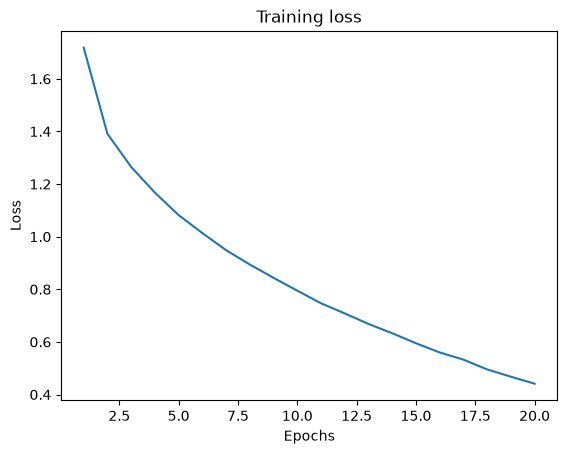

In [12]:
EPOCHS = 20

for epoch in range(EPOCHS):
    start = time.time()
    total_loss = 0

    for (batch, (img_tensor, target)) in enumerate(dataset):
        batch_loss, t_loss = train_step(img_tensor, target)
        total_loss += t_loss

        if batch % 100 == 0:
            print('Epoch {} Batch {} Loss {:.4f}'.format(
                epoch + 1, batch, batch_loss.numpy() / int(target.shape[1])))

    # Loss of the epoch
    loss_plot.append(total_loss / num_steps)

    print('Epoch {} Loss {:.6f}'.format(epoch + 1, total_loss / num_steps))
    print('Time taken for 1 epoch {:.0f} sec\n'.format(time.time() - start))

# Training loss curve
plt.plot(range(1, len(loss_plot) + 1), loss_plot)
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training loss')
plt.show()

**What to look for.** The loss should go down steadily during the 20 epochs. But this curve only shows that the model fits its **training** captions better and better: with only 1,600 training photos, a loss that keeps going down can also mean that the model learns these captions by heart. We do not measure the loss on unseen photos here, so we check it in Section 6.

# 5. Test: captions of test images

To caption a new image, we do the same as during training, but this time the network uses **its own prediction** as the next input word, since there is no real caption anymore. It stops when it writes `<end>` (or when it reaches the maximum length).

At each word we also keep the attention weights, so that we can show **which part of the image** the network was looking at when it wrote this word.

In [13]:
def evaluate(image):
    attention_plot = np.zeros((max_length, attention_features_shape))

    hidden = decoder.reset_state(batch_size=1)

    # Image -> InceptionV3 -> 64x2048 -> encoder
    temp_input = tf.expand_dims(load_image(image)[0], 0)
    img_tensor_val = image_features_extract_model(temp_input)
    img_tensor_val = tf.reshape(img_tensor_val, (img_tensor_val.shape[0], -1, img_tensor_val.shape[3]))
    features = encoder(img_tensor_val)

    dec_input = tf.expand_dims([tokenizer.word_index['<start>']], 0)
    result = []

    for i in range(max_length):
        predictions, hidden, attention_weights = decoder(dec_input, features, hidden)

        attention_plot[i] = tf.reshape(attention_weights, (-1, )).numpy()

        # Next word drawn from the predicted scores
        predicted_id = tf.random.categorical(predictions, 1)[0][0].numpy()
        result.append(tokenizer.index_word[predicted_id])

        if tokenizer.index_word[predicted_id] == '<end>':
            return result, attention_plot

        # The predicted word is the next input
        dec_input = tf.expand_dims([predicted_id], 0)

    attention_plot = attention_plot[:len(result), :]
    return result, attention_plot

# Shows, for each word, the attention map over the image
def plot_attention(image, result, attention_plot):
    temp_image = np.array(Image.open(image))

    fig = plt.figure(figsize=(10, 10))

    len_result = len(result)
    grid = math.ceil(math.sqrt(len_result))      # square grid big enough for all the words
    for l in range(len_result):
        temp_att = np.resize(attention_plot[l], (8, 8))
        ax = fig.add_subplot(grid, grid, l + 1)
        ax.set_title(result[l])
        img = ax.imshow(temp_image)
        ax.imshow(temp_att, cmap='gray', alpha=0.6, extent=img.get_extent())
        ax.axis('off')

    plt.tight_layout()
    plt.show()

A few test images: the real caption, the predicted one, and the attention map of each word.

Real Caption: <start> a city street with cars on the road <end>
Prediction Caption: people are cars are cars are riding through a city street <end>


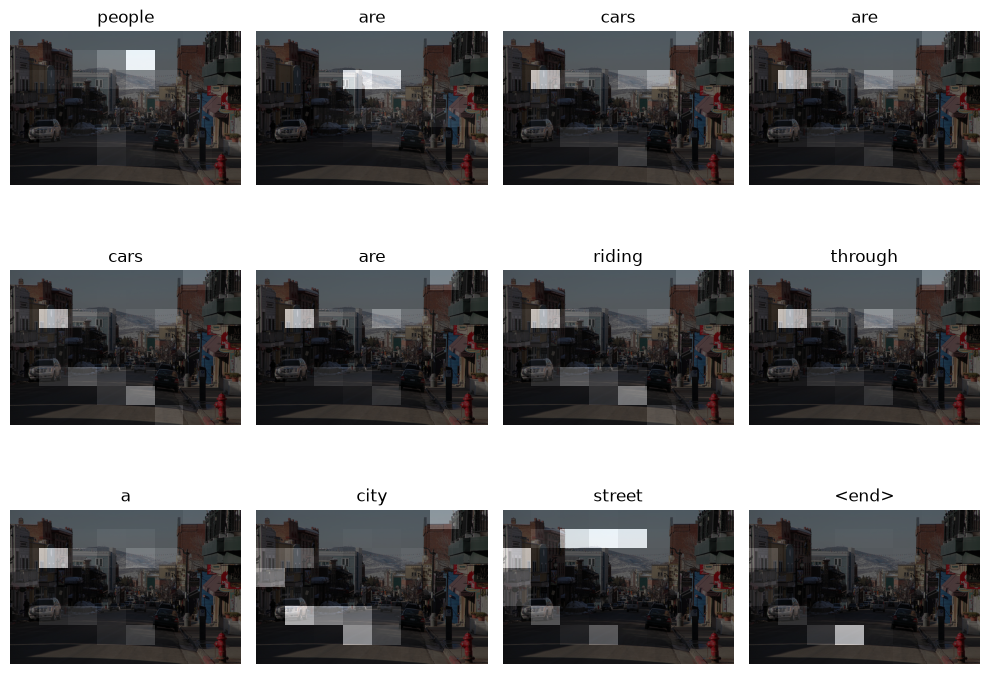

Real Caption: <start> a chef in a kitchen cutting up ingredients to use in a recipe <end>
Prediction Caption: a man prepare food <end>


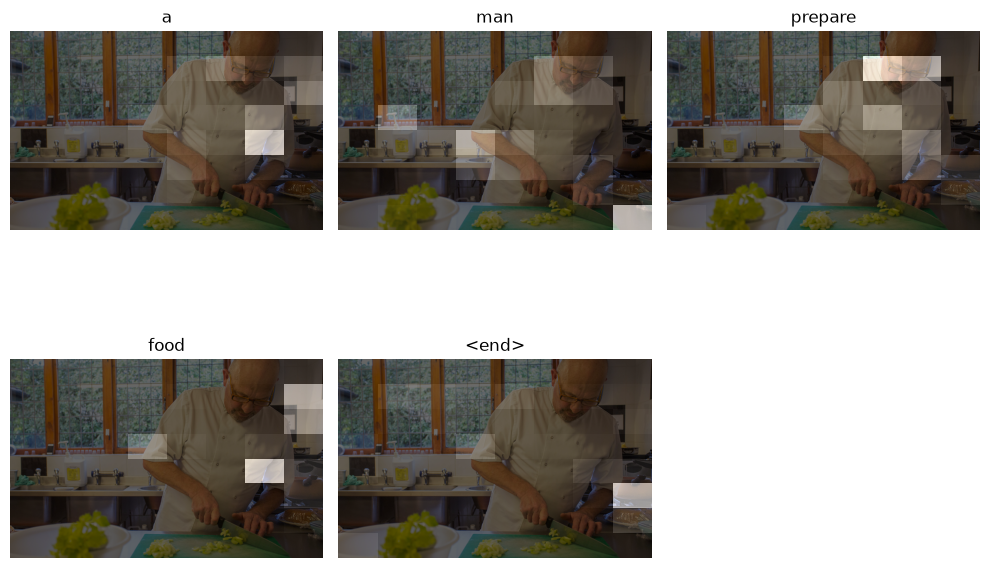

Real Caption: <start> bicycles are parked outside a small charming restaurant <end>
Prediction Caption: store up against a store <end>


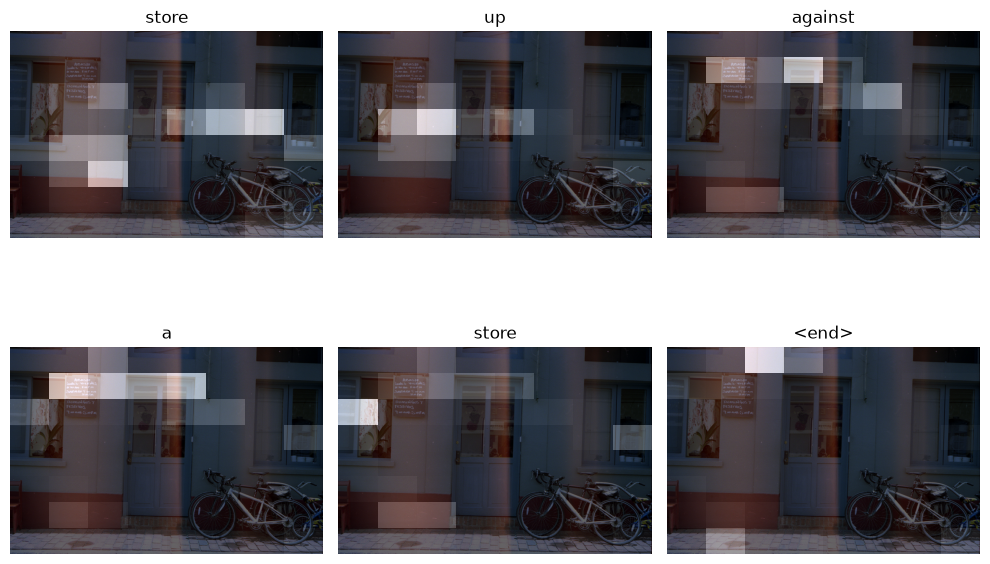

In [14]:
for rid in np.random.randint(0, len(img_name_val), 3):
    image = img_name_val[rid]
    real_caption = ' '.join([tokenizer.index_word[i] for i in cap_val[rid] if i not in [0]])
    result, attention_plot = evaluate(image)

    print('Real Caption:', real_caption)
    print('Prediction Caption:', ' '.join(result))
    plot_attention(image, result, attention_plot)

**What to look for.** Whether the predicted caption describes the main subject of the photo, and whether the sentence stays coherent until the end. The next word is drawn at random from the probabilities given by the network (`tf.random.categorical`): most of the time a likely word is drawn, but an unlikely one can also come out, and since each word is the input of the next step, the rest of the sentence follows it. It also means that the same photo gets a different caption each time.

# 6. Improving the model

The first model works in principle, but it learned from very little data: 1,600 training photos for a vocabulary of 5,000 words. We keep the same architecture (InceptionV3 features stored on disk, CNN encoder, attention and GRU decoder) and improve it with what we used in the other parts of the course:

1. **More data.** Section 2 takes the first 2,000 images of COCO. Here we take **30 % of COCO train 2014**, about 24,800 images and 124,000 captions. To compare the two models fairly, the **test photos are exactly the same as for the first model**.
2. **Pre-trained word vectors (GloVe).** Images already benefit from transfer learning through InceptionV3. We do the same for the words: the `Embedding` layer of the decoder starts from the **GloVe** vectors, learned on billions of words, instead of random values. A word seen only a few times in our captions then already has a meaningful vector ("puppy" is close to "dog").
3. **Dropout** in the decoder, to limit overfitting.
4. **A validation set and early stopping.** The first training ran 20 epochs blind. This time we measure the loss on validation photos after each epoch and keep the best epoch.
5. **A cleaner vocabulary.** It is built on the training captions only and keeps the words seen at least 5 times; the very long captions (more than 25 words, 0.2 %) are left out of the training.
6. **Beam search to write the captions.** In Section 5, each word is drawn at random from the predicted probabilities, which sometimes makes the sentence go off the rails; taking the most likely word instead tends to create loops (*"a street with a street with…"*). Beam search keeps the 3 best sentences at each step and returns the most likely one overall. It is the usual way to write captions with this kind of model, it always gives the same caption for the same photo, and it only changes how the trained model is used, not the model itself.

**A note on the loss.** The loss of `train_step` is averaged over all the positions of the captions, **including the `<pad>` positions**, which count as 0. Its value therefore depends on how much the captions are padded, and two models padded to different lengths cannot be compared with it. To compare the models, we use the **average loss per real word**: the sum of the losses of the real words divided by their number.

### 6.1 Was the first model overfitting?

We compute the average loss per word of the first model on its training photos and on its 400 test photos, without changing the weights.

In [15]:
def make_dataset(img_names, caps, shuffle_data=True):
    # Same (image, caption) pairs as Section 2, but the features of each image are read only once from disk
    # and then paired with each of its captions (about 5): 5 times less to read at every epoch
    names = np.asarray(img_names)
    order = np.argsort(names, kind="stable")
    caps_sorted = tf.constant(np.asarray(caps)[order], dtype=tf.int32)
    unique_names, starts, counts = np.unique(names[order], return_index=True, return_counts=True)

    ds = tf.data.Dataset.from_tensor_slices((unique_names, starts.astype(np.int32), counts.astype(np.int32)))
    if shuffle_data:
        ds = ds.shuffle(len(unique_names))                  # new order of the images at every epoch

    def load(name, start, count):
        feat = tf.numpy_function(lambda n: np.load(feature_path(n.decode('utf-8'))), [name], tf.float32)
        feat.set_shape((attention_features_shape, features_shape))
        return feat, caps_sorted[start:start + count]      # the features once, all the captions of the image

    ds = ds.map(load, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.flat_map(lambda feat, cap_group: tf.data.Dataset.from_tensor_slices(
        (tf.repeat(feat[None], tf.shape(cap_group)[0], axis=0), cap_group)))   # one pair per caption
    if shuffle_data:
        ds = ds.shuffle(BUFFER_SIZE)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

def masked_loss_sum(real, pred):
    # Sum of the losses of the real words (the <pad> positions are not counted), and number of real words
    mask = tf.cast(tf.math.not_equal(real, 0), tf.float32)
    return tf.reduce_sum(loss_object(real, pred) * mask), tf.reduce_sum(mask)

def make_loss_step(enc, dec, tok):
    # Same computation as train_step (teacher forcing), without updating the weights
    start_id = tok.word_index['<start>']

    @tf.function
    def loss_step(img_tensor, target):
        total, count = 0.0, 0.0
        hidden = dec.reset_state(batch_size=target.shape[0])
        dec_input = tf.expand_dims([start_id] * target.shape[0], 1)
        features = enc(img_tensor)
        for i in range(1, target.shape[1]):
            predictions, hidden, _ = dec(dec_input, features, hidden)
            s, n = masked_loss_sum(target[:, i], predictions)
            total += s
            count += n
            dec_input = tf.expand_dims(target[:, i], 1)
        return total, count
    return loss_step

def mean_word_loss(step, ds):
    # Average loss per real word over a whole dataset
    total, count = 0.0, 0.0
    for img_tensor, target in ds:
        s, n = step(img_tensor, target)
        total += float(s)
        count += float(n)
    return total / count

loss_step_v1 = make_loss_step(encoder, decoder, tokenizer)
train_loss_v1 = mean_word_loss(loss_step_v1, make_dataset(img_name_train, cap_train, shuffle_data=False))
test_loss_v1 = mean_word_loss(loss_step_v1, make_dataset(img_name_val, cap_val, shuffle_data=False))
print(f"First model, average loss per word: training photos {train_loss_v1:.3f} | test photos {test_loss_v1:.3f}")

First model, average loss per word: training photos 1.164 | test photos 4.889


**What to look for.** If the loss on the test photos is much higher than on the training photos, the first model learned its training captions by heart and does not generalise well.

### 6.2 More data: 30 % of COCO

We take 30 % of the images of COCO train 2014. We start with the images whose InceptionV3 features are already on disk (the 2,000 of the first model and those of earlier runs), then add the next images of the annotation file. The test photos of the first model stay the test photos; the other images are split into 90 % training and 10 % validation.

The missing images are downloaded **16 at a time** (one at a time would take about 3 hours), then their InceptionV3 features are computed and stored on disk exactly as in Section 2. This step is long the first time (about 20 minutes of download and 25 minutes of InceptionV3 on a CPU) and needs about **13 GB** of disk for the features; at the next runs, everything already on disk is skipped.

In [16]:
from concurrent.futures import ThreadPoolExecutor

SHARE_OF_COCO = 0.30
N_IMAGES_V2 = int(SHARE_OF_COCO * len(image_paths))

# First the images whose features are already on disk, then the next ones of the file
already_done = [p for p in image_paths if os.path.exists(feature_path(p))]
not_done = [p for p in image_paths if not os.path.exists(feature_path(p))]
v2_paths = already_done[:N_IMAGES_V2] + not_done[:max(0, N_IMAGES_V2 - len(already_done))]

test_keys_v2 = list(img_name_val_keys)                      # same test photos as the first model
test_set = set(test_keys_v2)
others = [p for p in v2_paths if p not in test_set]
random.Random(42).shuffle(others)
n_val = len(others) // 10
val_keys_v2, train_keys_v2 = others[:n_val], others[n_val:]

# Download the missing images, 16 at a time
def safe_download(p):
    try:
        download_image(p)
    except Exception:
        pass                                                 # checked just below

new_images = [p for p in v2_paths if not os.path.exists(feature_path(p))]
to_download = [p for p in tqdm(new_images, desc='checking') if not os.path.exists(p) or not image_ok(p)]
print(len(new_images), "images without features |", len(to_download), "to download")
with ThreadPoolExecutor(max_workers=16) as pool:
    list(tqdm(pool.map(safe_download, to_download), total=len(to_download), desc='downloading'))

# Images still unreadable are removed
still_bad = set(p for p in to_download if not image_ok(p))
if still_bad:
    print(len(still_bad), "unreadable image(s) removed")
train_keys_v2 = [p for p in train_keys_v2 if p not in still_bad]
val_keys_v2 = [p for p in val_keys_v2 if p not in still_bad]

# InceptionV3 features of the new images, stored on disk (same code as Section 2)
todo = [p for p in new_images if p not in still_bad]
if todo:
    new_dataset = tf.data.Dataset.from_tensor_slices(todo)
    new_dataset = new_dataset.map(load_image, num_parallel_calls=tf.data.AUTOTUNE).batch(16)
    for img, path in tqdm(new_dataset, desc='InceptionV3'):
        batch_features = image_features_extract_model(img)
        batch_features = tf.reshape(batch_features, (batch_features.shape[0], -1, batch_features.shape[3]))
        for bf, p in zip(batch_features, path):
            np.save(feature_path(p.numpy().decode("utf-8")), bf.numpy())

print(f"{len(v2_paths)} images: train {len(train_keys_v2)} | validation {len(val_keys_v2)} | test {len(test_keys_v2)}")

checking: 0it [00:00, ?it/s]


0 images without features | 0 to download


downloading: 0it [00:00, ?it/s]

24834 images: train 21991 | validation 2443 | test 400


### 6.3 Text pre-processing

Same steps as in Section 2 (splitting into words, most frequent words, indexes, padding), with two changes:

- the vocabulary is built on the **training captions only**, and keeps the words seen **at least 5 times**; the others become `<unk>`;
- the training and validation captions longer than **25 words** are left out. The test captions are all kept.

In [17]:
MAX_TOKENS = 25    # longest caption kept for training, <start> and <end> included (99.8 % of the captions)
MIN_COUNT = 5      # a word must appear at least 5 times in the training captions to be in the vocabulary
FILTERS = r'!"#$%&()*+.,-/:;=?@[\]^_`{|}~ '

def captions_of(keys):
    # One entry per (image, caption) pair
    names, caps = [], []
    for k in keys:
        names.extend([k] * len(image_path_to_caption[k]))
        caps.extend(image_path_to_caption[k])
    return names, caps

img_name_train2, train_captions2 = captions_of(train_keys_v2)
img_name_val2, val_captions2 = captions_of(val_keys_v2)
img_name_test2, test_captions2 = captions_of(test_keys_v2)

# Vocabulary: the words seen at least MIN_COUNT times in the training captions
word_counter = tf.keras.preprocessing.text.Tokenizer(filters=FILTERS)
word_counter.fit_on_texts(train_captions2)
n_frequent = sum(1 for count in word_counter.word_counts.values() if count >= MIN_COUNT)
vocab_size2 = n_frequent + 2                        # + <pad> (index 0) and <unk> (index 1)

tokenizer2 = tf.keras.preprocessing.text.Tokenizer(num_words=vocab_size2, oov_token="<unk>", filters=FILTERS)
tokenizer2.fit_on_texts(train_captions2)
tokenizer2.word_index['<pad>'] = 0
tokenizer2.index_word[0] = '<pad>'

def to_padded(names, captions, drop_long):
    seqs = tokenizer2.texts_to_sequences(captions)
    if drop_long:                                   # training and validation: very long captions left out
        keep = [len(s) <= MAX_TOKENS for s in seqs]
        names = [n for n, k in zip(names, keep) if k]
        seqs = [s for s, k in zip(seqs, keep) if k]
    return names, tf.keras.preprocessing.sequence.pad_sequences(seqs, padding='post')

img_name_train2, cap_train2 = to_padded(img_name_train2, train_captions2, drop_long=True)
img_name_val2, cap_val2 = to_padded(img_name_val2, val_captions2, drop_long=True)
img_name_test2, cap_test2 = to_padded(img_name_test2, test_captions2, drop_long=False)
max_length2 = MAX_TOKENS                            # longest caption the model will write

train_ds2 = make_dataset(img_name_train2, cap_train2)
val_ds2 = make_dataset(img_name_val2, cap_val2, shuffle_data=False)
test_ds2 = make_dataset(img_name_test2, cap_test2, shuffle_data=False)
print(f"Vocabulary: {vocab_size2} words (first model: {vocab_size})")
print(f"{len(cap_train2)} training, {len(cap_val2)} validation and {len(cap_test2)} test captions")

Vocabulary: 4658 words (first model: 5001)
109738 training, 12180 validation and 2001 test captions


### 6.4 Pre-trained word vectors (GloVe)

GloVe gives a vector of 100 values for 400,000 English words. We build an **embedding matrix** with one row per word of our vocabulary:

- if the word is in GloVe, its row is its GloVe vector;
- otherwise (`<start>`, `<end>`, `<unk>`, very rare spellings), its row starts with small random values between -0.05 and 0.05, so that the network still receives a signal for these words and can learn them.

This matrix is the starting point of the `Embedding` layer of the decoder, and it stays **trainable**: the network keeps the knowledge of GloVe and adapts the vectors to the captions of COCO. The GloVe file (`glove.6B.zip`, 822 MB) is downloaded once, next to the COCO data.

In [18]:
import zipfile

GLOVE_DIM = 100
GLOVE_DIR = os.path.join(COCO_DIR, "glove.6B")
GLOVE_FILE = os.path.join(GLOVE_DIR, "glove.6B.100d.txt")

if not os.path.exists(GLOVE_FILE):
    zip_path = os.path.join(COCO_DIR, "glove.6B.zip")
    if not os.path.exists(zip_path):
        urllib.request.urlretrieve("https://nlp.stanford.edu/data/glove.6B.zip", zip_path + ".part")
        os.replace(zip_path + ".part", zip_path)
    with zipfile.ZipFile(zip_path) as zf:
        zf.extract("glove.6B.100d.txt", GLOVE_DIR)

# Word -> vector of 100 values
embedding_dict = {}
with open(GLOVE_FILE, 'r', encoding='utf-8') as f:
    for line in f:
        values = line.split()
        embedding_dict[values[0]] = np.asarray(values[1:], 'float32')
print('Found %s word vectors.' % len(embedding_dict))

# Embedding matrix: GloVe vector if the word is known, small random values otherwise
embedding_matrix = np.random.uniform(-0.05, 0.05, size=(vocab_size2, GLOVE_DIM)).astype('float32')
hit, misses = 0, []
for word, i in tokenizer2.word_index.items():
    if i >= vocab_size2:
        continue
    emb_vec = embedding_dict.get(word)
    if emb_vec is not None:
        embedding_matrix[i] = emb_vec
        hit += 1
    else:
        misses.append(word)
print(f"{hit} words of the vocabulary found in GloVe, {len(misses)} not found:", misses[:15])

Found 400000 word vectors.
4593 words of the vocabulary found in GloVe, 65 not found: ['<unk>', '<start>', '<end>', "it's", '\n', 'selfie', "giraffe's", "person's", "man's", "someone's", "that's", "woman's", 'deckered', "men's", "driver's"]


### 6.5 Training with validation, early stopping and dropout

The decoder is the same as before, with two changes:

- its `Embedding` layer starts from the GloVe matrix (vectors of 100 values instead of 256);
- **dropout** (30 %) at two places, on the input of the GRU and before the last layer. During training, a random part of these values is set to 0 at each step, so the network cannot rely on a few specific neurons and has to learn more general rules; when writing a caption, dropout is switched off.

The training step is the same as in Section 4. After each epoch we compute the loss per word on the validation photos; the weights of the best epoch are saved, and the training stops when the validation loss has not improved for 3 epochs.

With 4 times more captions than the first model, an epoch takes about 10 minutes on our laptop GPU, so the whole training takes about 2 hours. To keep the GPU busy, `make_dataset` reads the features of each image only once per epoch and pairs them with its ~5 captions, instead of reading the same file 5 times.

The training runs in its **own process**: the first cell below writes the training code to `captioning_train.py`, the second one runs it. On our laptop the GPU sometimes fails during a long training (it happened twice, after 20 minutes and after 100 minutes), and such an error kills the whole Python process, so the notebook with it. In a separate process, only the training stops: the notebook starts it again 30 seconds later, and it resumes after the last finished epoch, because the state of each epoch (weights, optimizer and loss history) is saved. At the end, the weights of the best epoch are loaded back into the notebook.

We save the weights with Keras `save_weights` and not with `tf.train.Checkpoint`: with our version of Keras, the checkpoint only kept the dense layers and silently lost the GRU and the attention, so a resumed training started again with half of the network random.

In [19]:
%%writefile captioning_train.py
# Training of the second captioning model (Section 6.5). The notebook runs this file in its own process:
# if the GPU fails, only this process stops, and the notebook starts it again from the last saved epoch.
import json
import os
import sys
import time

import numpy as np
import tensorflow as tf

ATTENTION_FEATURES, FEATURES = 64, 2048       # InceptionV3 features: 64 regions x 2048 values


class CNN_Encoder(tf.keras.Model):
    # Same as Section 3: one dense layer + ReLU on each of the 64 regions
    def __init__(self, embedding_dim):
        super(CNN_Encoder, self).__init__()
        self.fc = tf.keras.layers.Dense(embedding_dim)

    def call(self, x):
        return tf.nn.relu(self.fc(x))


class BahdanauAttention(tf.keras.Model):
    # Same as Section 3: one weight per region, context vector = weighted sum of the regions
    def __init__(self, units):
        super(BahdanauAttention, self).__init__()
        self.W1 = tf.keras.layers.Dense(units)
        self.W2 = tf.keras.layers.Dense(units)
        self.V = tf.keras.layers.Dense(1)

    def call(self, features, hidden):
        hidden_with_time_axis = tf.expand_dims(hidden, 1)
        attention_hidden_layer = tf.nn.tanh(self.W1(features) + self.W2(hidden_with_time_axis))
        attention_weights = tf.nn.softmax(self.V(attention_hidden_layer), axis=1)
        context_vector = tf.reduce_sum(attention_weights * features, axis=1)
        return context_vector, attention_weights


class RNN_Decoder(tf.keras.Model):
    # Same as Section 3
    def __init__(self, embedding_dim, units, vocab_size):
        super(RNN_Decoder, self).__init__()
        self.units = units
        self.embedding = tf.keras.layers.Embedding(vocab_size, embedding_dim)
        self.gru = tf.keras.layers.GRU(self.units, return_sequences=True, return_state=True,
                                       recurrent_initializer='glorot_uniform')
        self.fc1 = tf.keras.layers.Dense(self.units)
        self.fc2 = tf.keras.layers.Dense(vocab_size)
        self.attention = BahdanauAttention(self.units)

    def reset_state(self, batch_size):
        return tf.zeros((batch_size, self.units))


class RNN_Decoder_v2(RNN_Decoder):
    # Same decoder, with GloVe word vectors and dropout (active only during training)
    def __init__(self, embedding_dim, units, vocab_size, embedding_matrix, dropout_rate=0.3):
        super(RNN_Decoder_v2, self).__init__(embedding_dim, units, vocab_size)
        # Word vectors initialised with GloVe, still trainable
        self.embedding = tf.keras.layers.Embedding(vocab_size, embedding_dim,
                                                   embeddings_initializer=tf.keras.initializers.Constant(embedding_matrix),
                                                   trainable=True)
        self.dropout = tf.keras.layers.Dropout(dropout_rate)

    def call(self, x, features, hidden, training=False):
        context_vector, attention_weights = self.attention(features, hidden)
        x = self.embedding(x)
        x = tf.concat([tf.expand_dims(context_vector, 1), x], axis=-1)
        x = self.dropout(x, training=training)          # dropout on the input of the GRU
        output, state = self.gru(x)
        y = self.fc1(output)
        y = tf.reshape(y, (-1, y.shape[2]))
        y = self.dropout(y, training=training)          # dropout before the last layer
        y = self.fc2(y)
        return y, state, attention_weights


def build(enc, dec):
    # One call on an empty input so that every layer creates its weights (needed before loading saved weights)
    features = enc(tf.zeros((1, ATTENTION_FEATURES, FEATURES)))
    dec(tf.zeros((1, 1), tf.int32), features, dec.reset_state(1))


loss_object = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True, reduction='none')

def loss_function(real, pred):
    # Same as Section 3: the <pad> positions are not counted
    mask = tf.cast(tf.math.not_equal(real, 0), tf.float32)
    return tf.reduce_mean(loss_object(real, pred) * mask)

def masked_loss_sum(real, pred):
    # Sum of the losses of the real words, and number of real words
    mask = tf.cast(tf.math.not_equal(real, 0), tf.float32)
    return tf.reduce_sum(loss_object(real, pred) * mask), tf.reduce_sum(mask)


def make_dataset(feature_files, caps, batch_size, buffer_size, shuffle_data=True):
    # Same as make_dataset (Section 6.1): the features of each image are read once, then paired with its captions
    files = np.asarray(feature_files)
    order = np.argsort(files, kind="stable")
    caps_sorted = tf.constant(np.asarray(caps)[order], dtype=tf.int32)
    unique_files, starts, counts = np.unique(files[order], return_index=True, return_counts=True)

    ds = tf.data.Dataset.from_tensor_slices((unique_files, starts.astype(np.int32), counts.astype(np.int32)))
    if shuffle_data:
        ds = ds.shuffle(len(unique_files))

    def load(path, start, count):
        feat = tf.numpy_function(lambda p: np.load(p.decode("utf-8")), [path], tf.float32)
        feat.set_shape((ATTENTION_FEATURES, FEATURES))
        return feat, caps_sorted[start:start + count]

    ds = ds.map(load, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.flat_map(lambda feat, cap_group: tf.data.Dataset.from_tensor_slices(
        (tf.repeat(feat[None], tf.shape(cap_group)[0], axis=0), cap_group)))
    if shuffle_data:
        ds = ds.shuffle(buffer_size)
    return ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)


def make_steps(enc, dec, opt, start_id):
    # Training step (same as Section 4, teacher forcing) and loss step (same thing, without updating the weights).
    # Both return the sum of the losses of the real words and their number.
    @tf.function
    def train_step(img_tensor, target):
        loss, total, count = 0.0, 0.0, 0.0
        hidden = dec.reset_state(batch_size=target.shape[0])
        dec_input = tf.expand_dims([start_id] * target.shape[0], 1)
        with tf.GradientTape() as tape:
            features = enc(img_tensor)
            for i in range(1, target.shape[1]):
                predictions, hidden, _ = dec(dec_input, features, hidden, training=True)
                loss += loss_function(target[:, i], predictions)
                s, n = masked_loss_sum(target[:, i], predictions)
                total += s
                count += n
                dec_input = tf.expand_dims(target[:, i], 1)
        trainable_variables = enc.trainable_variables + dec.trainable_variables
        gradients = tape.gradient(loss, trainable_variables)
        opt.apply_gradients(zip(gradients, trainable_variables))
        return total, count

    @tf.function
    def loss_step(img_tensor, target):
        total, count = 0.0, 0.0
        hidden = dec.reset_state(batch_size=target.shape[0])
        dec_input = tf.expand_dims([start_id] * target.shape[0], 1)
        features = enc(img_tensor)
        for i in range(1, target.shape[1]):
            predictions, hidden, _ = dec(dec_input, features, hidden)
            s, n = masked_loss_sum(target[:, i], predictions)
            total += s
            count += n
            dec_input = tf.expand_dims(target[:, i], 1)
        return total, count

    return train_step, loss_step


def mean_word_loss(step, ds):
    # Average loss per real word over a whole dataset
    total, count = 0.0, 0.0
    for img_tensor, target in ds:
        s, n = step(img_tensor, target)
        total += float(s)
        count += float(n)
    return total / count


def save_state(enc, dec, opt, folder, with_optimizer=False):
    # save_weights keeps every layer (GRU and attention included)
    enc.save_weights(os.path.join(folder, "encoder.weights.h5"))
    dec.save_weights(os.path.join(folder, "decoder.weights.h5"))
    if with_optimizer:
        np.savez(os.path.join(folder, "optimizer.npz"), *[v.numpy() for v in opt.variables])

def load_state(enc, dec, opt, folder, with_optimizer=False):
    enc.load_weights(os.path.join(folder, "encoder.weights.h5"))
    dec.load_weights(os.path.join(folder, "decoder.weights.h5"))
    if with_optimizer:
        saved = np.load(os.path.join(folder, "optimizer.npz"))
        for v, k in zip(opt.variables, saved.files):
            v.assign(saved[k])


def main(data_file):
    # The GPU memory is taken as needed, the notebook also uses some
    for gpu in tf.config.list_physical_devices("GPU"):
        tf.config.experimental.set_memory_growth(gpu, True)

    data = np.load(data_file)
    cfg = json.loads(str(data["config"]))
    train_ds = make_dataset(data["train_files"], data["train_caps"], cfg["batch_size"], cfg["buffer_size"])
    val_ds = make_dataset(data["val_files"], data["val_caps"], cfg["batch_size"], cfg["buffer_size"], shuffle_data=False)

    encoder = CNN_Encoder(cfg["embedding_dim"])
    decoder = RNN_Decoder_v2(cfg["glove_dim"], cfg["units"], cfg["vocab_size"], data["embedding_matrix"])
    optimizer = tf.keras.optimizers.Adam()
    build(encoder, decoder)
    optimizer.build(encoder.trainable_variables + decoder.trainable_variables)
    train_step, loss_step = make_steps(encoder, decoder, optimizer, cfg["start_id"])

    best_dir, last_dir = cfg["best_dir"], cfg["last_dir"]
    os.makedirs(best_dir, exist_ok=True)
    os.makedirs(last_dir, exist_ok=True)
    history_file = os.path.join(last_dir, "history.json")
    train_hist, val_hist, best_val, wait = [], [], float("inf"), 0

    # After a stop (GPU error...), resume after the last finished epoch
    if os.path.exists(history_file):
        load_state(encoder, decoder, optimizer, last_dir, with_optimizer=True)
        with open(history_file) as f:
            state = json.load(f)
        train_hist, val_hist, best_val, wait = state["train"], state["val"], state["best_val"], state["wait"]
        print(f"Resuming after epoch {len(train_hist)} (best validation loss so far: {best_val:.4f})", flush=True)

    for epoch in range(len(train_hist), cfg["epochs"]):
        if wait >= cfg["patience"]:                      # the training had already stopped
            break
        start = time.time()
        train_loss = mean_word_loss(train_step, train_ds)    # one pass on the training set, with weight updates
        val_loss = mean_word_loss(loss_step, val_ds)
        train_hist.append(train_loss)
        val_hist.append(val_loss)
        print(f"Epoch {epoch + 1} | training loss {train_loss:.4f} | validation loss {val_loss:.4f} | "
              f"{time.time() - start:.0f} sec", flush=True)

        if val_loss < best_val:
            best_val, wait = val_loss, 0
            save_state(encoder, decoder, optimizer, best_dir)            # weights of the best epoch so far
        else:
            wait += 1

        # State of this epoch, to be able to resume from here
        save_state(encoder, decoder, optimizer, last_dir, with_optimizer=True)
        with open(history_file, "w") as f:
            json.dump({"train": train_hist, "val": val_hist, "best_val": best_val, "wait": wait}, f)

        if wait >= cfg["patience"]:
            print(f"Early stopping: no improvement for {cfg['patience']} epochs", flush=True)
            break


if __name__ == "__main__":
    try:
        main(sys.argv[1])
    except (tf.errors.InternalError, tf.errors.UnknownError) as e:
        print("GPU error:", str(e).splitlines()[0], flush=True)
        sys.exit(3)                                       # the notebook starts the training again


Overwriting captioning_train.py


In [20]:
import importlib
import subprocess
import sys
import captioning_train as ct
importlib.reload(ct)                    # in case the file was just written again

BEST_DIR, LAST_DIR = "./checkpoints/v2_best", "./checkpoints/v2_last"
EPOCHS_V2 = 30          # maximum
PATIENCE_V2 = 3         # epochs without improvement of the validation loss before stopping
MAX_RESTARTS = 10       # GPU errors accepted before giving up

# Everything the training process needs, in one file
DATA_FILE = "./checkpoints/v2_data.npz"
os.makedirs("./checkpoints", exist_ok=True)
config = {"embedding_dim": embedding_dim, "glove_dim": GLOVE_DIM, "units": units, "vocab_size": vocab_size2,
          "start_id": tokenizer2.word_index['<start>'], "batch_size": BATCH_SIZE, "buffer_size": BUFFER_SIZE,
          "epochs": EPOCHS_V2, "patience": PATIENCE_V2, "best_dir": BEST_DIR, "last_dir": LAST_DIR}
np.savez(DATA_FILE, config=json.dumps(config), embedding_matrix=embedding_matrix,
         train_files=np.array([feature_path(n) for n in img_name_train2]), train_caps=cap_train2,
         val_files=np.array([feature_path(n) for n in img_name_val2]), val_caps=cap_val2)

# Training in its own process. After a GPU error it is started again, and resumes after the last finished epoch
env = dict(os.environ, TF_CPP_MIN_LOG_LEVEL="2", PYTHONWARNINGS="ignore")
for attempt in range(MAX_RESTARTS + 1):
    proc = subprocess.Popen([sys.executable, "-u", "captioning_train.py", DATA_FILE], env=env,
                            stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    try:
        for line in proc.stdout:
            print(line, end="")
        proc.wait()
    finally:
        if proc.poll() is None:
            proc.kill()                 # stopping this cell also stops the training
    if proc.returncode == 0:
        break
    if proc.returncode == 1:
        raise RuntimeError("The training stopped on an error in the code (see above)")
    print(f"--- The training process stopped (GPU error, code {proc.returncode}): it starts again in 30 s ---")
    time.sleep(30)
else:
    raise RuntimeError(f"The training stopped {MAX_RESTARTS + 1} times, giving up")

# The best epoch, back in the notebook
encoder2 = ct.CNN_Encoder(embedding_dim)
decoder2 = ct.RNN_Decoder_v2(GLOVE_DIM, units, vocab_size2, embedding_matrix)
ct.build(encoder2, decoder2)
encoder2.load_weights(os.path.join(BEST_DIR, "encoder.weights.h5"))
decoder2.load_weights(os.path.join(BEST_DIR, "decoder.weights.h5"))
loss_step2 = make_loss_step(encoder2, decoder2, tokenizer2)

with open(os.path.join(LAST_DIR, "history.json")) as f:
    state = json.load(f)
train_hist2, val_hist2 = state["train"], state["val"]
best_epoch2 = int(np.argmin(val_hist2)) + 1
print(f"Best epoch: {best_epoch2} | validation loss {min(val_hist2):.4f}")


I0000 00:00:1793695775.171258   15491 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793695787.147755   15491 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
Resuming after epoch 7 (best validation loss so far: 2.7442)
Epoch 8 | training loss 2.6594 | validation loss 2.7367 | 635 sec
Epoch 9 | training loss 2.6291 | validation loss 2.7225 | 601 sec
Epoch 10 | training loss 2.6014 | validation loss 2.7389 | 607 sec
Epoch 11 | training loss 2.5755 | validation loss 2.7163 | 603 sec
Epoch 12 | training loss 2.5512 | validation loss 2.7145 | 606 sec
Epoch 13 | training loss 2.5331 | validation

/home/haytam/miniforge3/envs/leyenda/lib/python3.12/site-packages/keras/src/layers/layer.py:431: UserWarning: `build()` was called on layer 'rnn__decoder_v2', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(


Best epoch: 12 | validation loss 2.7145


### 6.6 Loss curves

The training and validation losses of the second model (average loss per word), with the loss of the first model on the test photos for comparison.

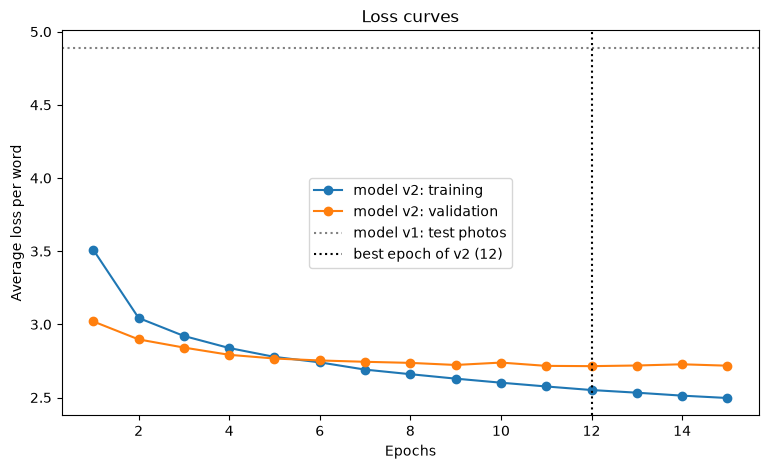

Average loss per word on the test photos: v1 4.889 | v2 2.868


In [21]:
test_loss_v2 = mean_word_loss(loss_step2, test_ds2)

plt.figure(figsize=(9, 5))
plt.plot(range(1, len(train_hist2) + 1), train_hist2, marker="o", label="model v2: training")
plt.plot(range(1, len(val_hist2) + 1), val_hist2, marker="o", label="model v2: validation")
plt.axhline(test_loss_v1, color="grey", ls=":", label="model v1: test photos")
plt.axvline(best_epoch2, color="black", ls=":", label=f"best epoch of v2 ({best_epoch2})")
plt.xlabel("Epochs")
plt.ylabel("Average loss per word")
plt.title("Loss curves")
plt.legend()
plt.show()

print(f"Average loss per word on the test photos: v1 {test_loss_v1:.3f} | v2 {test_loss_v2:.3f}")

**What to look for.** The validation curve tells whether the model generalises: it should go down with the training curve and stay close to it. The two test losses are measured on the same photos and the same captions; they are only roughly comparable, since each model has its own vocabulary.

### 6.7 Captions of the same test photos

`generate_caption` writes a caption like `evaluate` (Section 5), for a given model: by default each word is drawn from the predicted probabilities, as in Section 5; with `greedy=True` the most likely word is taken at each step.

`beam_search_caption` writes the caption with **beam search**. Instead of keeping only one sentence, it keeps the **3 best sentences** at each step: each one is extended with its 3 most likely next words, and the 3 best of these 9 candidates are kept. The score of a sentence is the sum of the log-probabilities of its words, divided by its length so that short sentences are not favoured. A sentence is not allowed to repeat a pair of words it already contains, which prevents the loops. The search goes on until all the candidate sentences have reached `<end>` (or 25 words), and the best finished sentence is returned.

We compare, on the same test photos, the real captions, the first model, and the second model with the three ways of choosing the words.

In [22]:
def encode_image(image, enc):
    # Image -> InceptionV3 -> 64x2048 -> encoder
    temp_input = tf.expand_dims(load_image(image)[0], 0)
    img_tensor_val = image_features_extract_model(temp_input)
    img_tensor_val = tf.reshape(img_tensor_val, (img_tensor_val.shape[0], -1, img_tensor_val.shape[3]))
    return enc(img_tensor_val)

def generate_caption(image, enc, dec, tok, max_len, greedy=False):
    attention_plot = np.zeros((max_len, attention_features_shape))
    hidden = dec.reset_state(batch_size=1)
    features = encode_image(image, enc)
    dec_input = tf.expand_dims([tok.word_index['<start>']], 0)
    result = []
    for i in range(max_len):
        predictions, hidden, attention_weights = dec(dec_input, features, hidden)
        attention_plot[i] = tf.reshape(attention_weights, (-1, )).numpy()
        if greedy:
            predicted_id = int(tf.argmax(predictions[0]).numpy())                   # most likely word
        else:
            predicted_id = int(tf.random.categorical(predictions, 1)[0][0].numpy())   # drawn at random
        result.append(tok.index_word.get(predicted_id, '<unk>'))
        if result[-1] == '<end>':
            break
        dec_input = tf.expand_dims([predicted_id], 0)
    return result, attention_plot[:len(result), :]

def repeats_pair(tokens):
    # True if the last two words already appear together earlier in the sentence
    if len(tokens) < 3:
        return False
    last = (tokens[-2], tokens[-1])
    return any((tokens[i], tokens[i + 1]) == last for i in range(len(tokens) - 2))

def beam_search_caption(image, enc, dec, tok, max_len, beam_width=3):
    features = encode_image(image, enc)
    start_id, end_id = tok.word_index['<start>'], tok.word_index['<end>']
    # A candidate sentence: (word indexes, sum of log-probabilities, hidden state of the GRU, attention weights)
    beams = [([start_id], 0.0, dec.reset_state(batch_size=1), [])]
    finished = []
    for _ in range(max_len):
        candidates = []
        for tokens, score, hidden, att in beams:
            predictions, new_hidden, attention_weights = dec(tf.expand_dims([tokens[-1]], 0), features, hidden)
            log_probs = tf.nn.log_softmax(predictions[0]).numpy()
            added = 0
            for w in np.argsort(log_probs)[::-1]:              # most likely words first
                w = int(w)
                if w == 0 or repeats_pair(tokens + [w]):        # no <pad>, no repeated pair of words
                    continue
                candidates.append((tokens + [w], score + log_probs[w], new_hidden,
                                   att + [attention_weights.numpy().reshape(-1)]))
                added += 1
                if added == beam_width:
                    break
        # Best candidates first (score divided by the length, so that short sentences are not favoured):
        # the sentences that reached <end> are finished, the 3 best others continue
        score = lambda c: c[1] / len(c[0])
        candidates.sort(key=score, reverse=True)
        beams = []
        for c in candidates:
            if c[0][-1] == end_id:
                finished.append(c)
            else:
                beams.append(c)
            if len(beams) == beam_width:
                break
        # Stop when every candidate sentence has reached <end> (or at the maximum length)
        if not beams:
            break
    best = max(finished if finished else beams, key=lambda c: c[1] / len(c[0]))
    words = [tok.index_word.get(t, '<unk>') for t in best[0][1:]]
    return words, np.array(best[3])

clean = lambda words: ' '.join(w for w in words if w not in ('<start>', '<end>'))


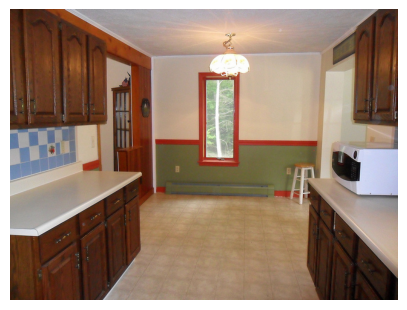

Real captions:           an empty kitchen with brown cupboards and a white microwave / An empty looking kitchen has red accents on the window.
v1 (drawn words):        this is a room
v2 (drawn words):        older kitchen with hard and a toilet and a sink
v2 (most likely words):  a kitchen with a sink and a sink
v2 (beam search):        a kitchen with wooden cabinets and a sink



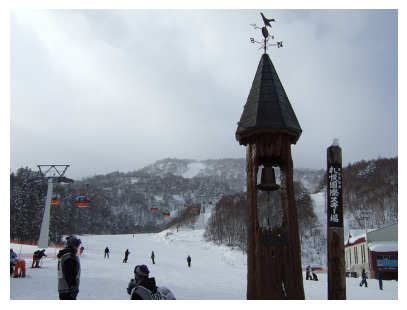

Real captions:           A ski slope has many people and a bell with a weather vane. / Many snowboarders are descending a small snowy hill.
v1 (drawn words):        people are about skis are ski types with people at a snow covered with several people at snow
v2 (drawn words):        the crowd of people with skis on a snowy country
v2 (most likely words):  a group of people on a snowy day
v2 (beam search):        a group of people walking down a snow covered field



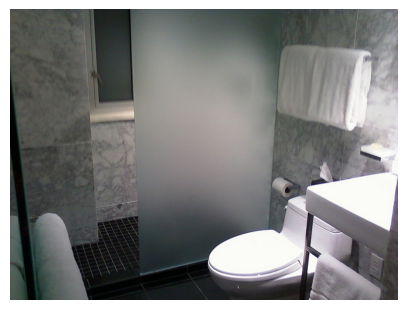

Real captions:           An empty bathroom with a sink and toilette underneath a hand drying towel. / A bathroom with a toilet and a shower.
v1 (drawn words):        a toilet
v2 (drawn words):        a break room with black tile counter and the window sink
v2 (most likely words):  a bathroom with a sink and a window
v2 (beam search):        a bathroom with a sink and a window



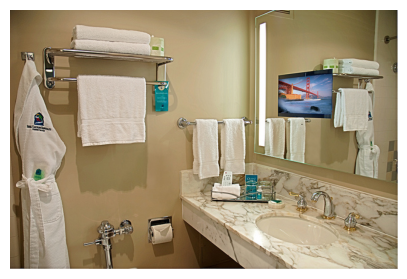

Real captions:           A bathroom in which are hung white towels and a white bathrobe.  / Bathroom with a lot of towels and a tv
v1 (drawn words):        bath tub in front of a clean bathroom with a mirror
v2 (drawn words):        a sink and a <unk> beside it
v2 (most likely words):  a bathroom with a sink and a sink
v2 (beam search):        a bathroom with a sink and a mirror



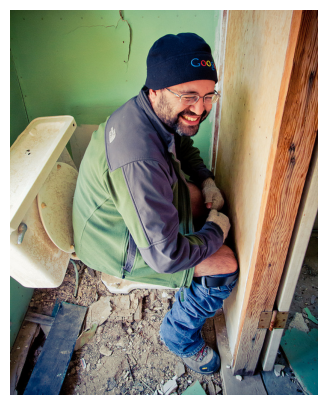

Real captions:           A man is playfully sitting on a toilet in a room being renovated, / The man in a google cap is sitting on the toilet.
v1 (drawn words):        a man standing on a stove
v2 (drawn words):        a man kneeling on a toilet in a bathroom
v2 (most likely words):  a man in a darth vader helmet
v2 (beam search):        a man in a darth vader helmet



In [23]:
for image in np.random.default_rng(0).choice(test_keys_v2, 5, replace=False):
    plt.figure(figsize=(5, 5))
    plt.imshow(Image.open(image))
    plt.axis("off")
    plt.show()
    print("Real captions:          ", " / ".join(c.replace('<start> ', '').replace(' <end>', '') for c in image_path_to_caption[image][:2]))
    print("v1 (drawn words):       ", clean(generate_caption(image, encoder, decoder, tokenizer, max_length)[0]))
    print("v2 (drawn words):       ", clean(generate_caption(image, encoder2, decoder2, tokenizer2, max_length2)[0]))
    print("v2 (most likely words): ", clean(generate_caption(image, encoder2, decoder2, tokenizer2, max_length2, greedy=True)[0]))
    print("v2 (beam search):       ", clean(beam_search_caption(image, encoder2, decoder2, tokenizer2, max_length2)[0]))
    print()

And where the second model looks when it writes each word, on one of these photos:

v2 caption (beam search): a man riding a bike with a dog on the back of a bicycle


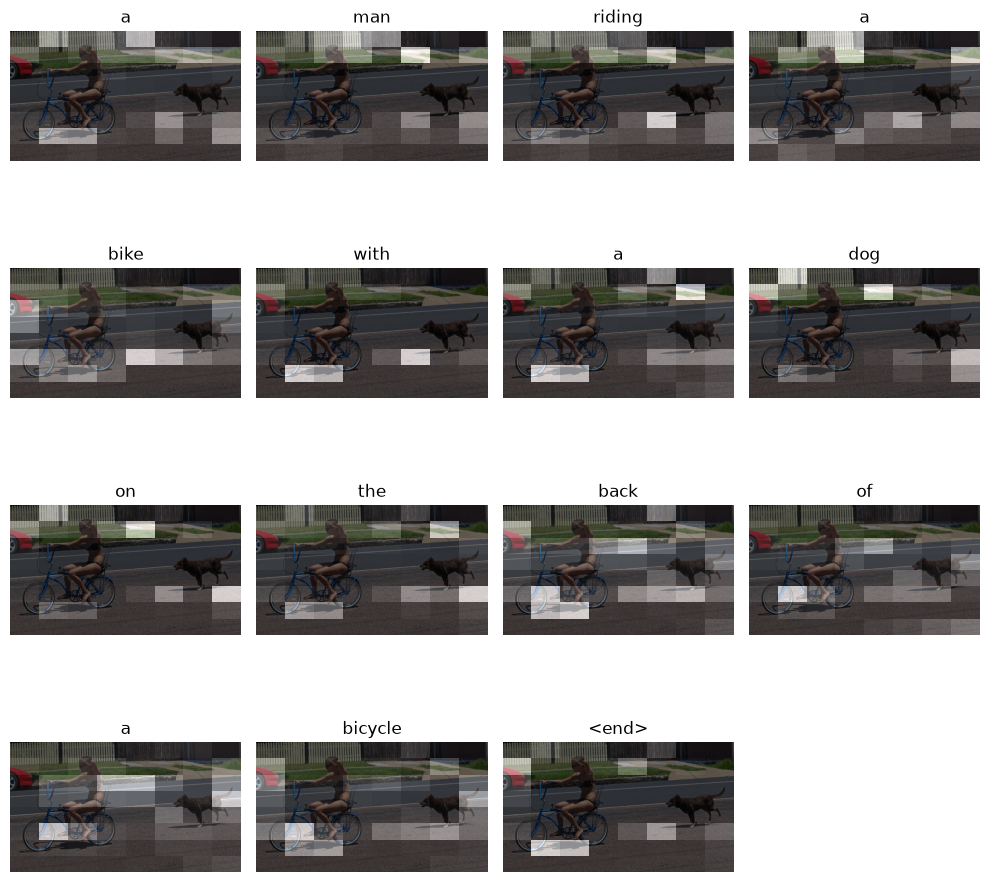

In [24]:
image = test_keys_v2[0]
result, attention_plot = beam_search_caption(image, encoder2, decoder2, tokenizer2, max_length2)
print("v2 caption (beam search):", clean(result))
plot_attention(image, result, attention_plot)

**What to look for.** Whether the second model, trained on more photos and with GloVe vectors, describes the scenes more accurately than the first one, and how the way of choosing the words changes the captions: drawing them can produce sentences that go off the rails, taking the most likely word can produce repetitions, and beam search should give the most coherent captions.

### 6.8 Saving the captioning model

Training the model takes time, so we save it to reuse it later (for instance in production at TouNum) without training it again. Our encoder and decoder are custom models (Python classes), so we save their **weights**, together with what is needed to rebuild them: the **tokenizer** (the vocabulary, to turn words into indexes and back) and the **sizes** of the network (vocabulary, word vectors, GRU, maximum caption length).


In [25]:
# Save the captioning model (v2) so that it can be reused without training again
SAVE_DIR = local_path(r"C:\Projet data\modele_captioning")
os.makedirs(SAVE_DIR, exist_ok=True)

# Weights of the encoder and the decoder
encoder2.save_weights(os.path.join(SAVE_DIR, "encoder.weights.h5"))
decoder2.save_weights(os.path.join(SAVE_DIR, "decoder.weights.h5"))

# Vocabulary (words <-> indexes)
with open(os.path.join(SAVE_DIR, "tokenizer.json"), "w", encoding="utf-8") as f:
    f.write(tokenizer2.to_json())

# Sizes needed to rebuild the network
with open(os.path.join(SAVE_DIR, "config.json"), "w") as f:
    json.dump({"embedding_dim": embedding_dim, "glove_dim": GLOVE_DIM, "units": units,
               "vocab_size": vocab_size2, "max_length": max_length2}, f)

print("Captioning model saved in", SAVE_DIR, ":", sorted(os.listdir(SAVE_DIR)))


Captioning model saved in /mnt/c/Projet data/modele_captioning : ['config.json', 'decoder.weights.h5', 'encoder.weights.h5', 'tokenizer.json']


# 7. The complete workflow: from an unidentified image to a captioned photo

The three deliverables are now put together. For each image of a folder:

```
 unidentified image
        │
        ▼
 [Deliverable 1] Is it a photo?  (CNN classifier, modele_photo_improved.keras)
        │ no  ──►  set aside, no caption
        │ yes
        ▼
 [Deliverable 2] Denoising  (U-Net, denoiser_rgb_v3.keras)
        │
        ▼
 [Deliverable 3] Captioning  (InceptionV3 → CNN encoder → attention + GRU)
        │
        ▼
 captioned photo
```

- **Step 1** uses the improved classifier of Deliverable 1 (dropout, data augmentation, early stopping). Like during its training, it takes 180×180 images.
- **Step 2** uses the best denoiser of Deliverable 2, the U-Net (v3, 29.9 dB of PSNR against 28.1 dB for the auto-encoder v2). It was trained on patches at the real resolution, so it works on photos of any size. The photos are first reduced to at most 640 pixels, the size of the photos of Deliverable 2, which also keeps the memory use reasonable on large photos. The denoised photo is saved in the output folder.
- **Step 3** captions the denoised photo with the improved network of Section 6, using beam search.

The cell below reloads the captioning model saved in 6.8, so this section also works without training again. After a restart of the kernel, first run the libraries cell (Section 2) and the functions of 6.7, then this section. The model classes come from `captioning_train.py` (Section 6.5).

In [26]:
# Reload the captioning model saved in 6.8, so this section works without training again
def local_path(windows_path):
    # Under Linux (WSL), C:\... becomes /mnt/c/...
    if os.name == "nt":
        return windows_path
    return "/mnt/" + windows_path[0].lower() + windows_path[2:].replace("\\", "/")

# InceptionV3, same as Section 2: image -> 8x8x2048 features
image_model = tf.keras.applications.InceptionV3(include_top=False, weights='imagenet')
image_features_extract_model = tf.keras.Model(image_model.input, image_model.layers[-1].output)
attention_features_shape, features_shape = 64, 2048

def load_image(image_path):
    img = tf.io.read_file(image_path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, (299, 299))
    img = tf.keras.applications.inception_v3.preprocess_input(img)
    return img, image_path

import captioning_train as ct          # the model classes (CNN encoder, attention, GRU decoder)

SAVE_DIR = local_path(r"C:\Projet data\modele_captioning")
with open(os.path.join(SAVE_DIR, "config.json")) as f:
    cfg = json.load(f)
with open(os.path.join(SAVE_DIR, "tokenizer.json"), encoding="utf-8") as f:
    tokenizer2 = tf.keras.preprocessing.text.tokenizer_from_json(f.read())
vocab_size2, max_length2, GLOVE_DIM = cfg["vocab_size"], cfg["max_length"], cfg["glove_dim"]

encoder2 = ct.CNN_Encoder(cfg["embedding_dim"])
decoder2 = ct.RNN_Decoder_v2(GLOVE_DIM, cfg["units"], vocab_size2, np.zeros((vocab_size2, GLOVE_DIM), "float32"))

ct.build(encoder2, decoder2)          # the layers create their weights, then the saved weights replace them
encoder2.load_weights(os.path.join(SAVE_DIR, "encoder.weights.h5"))
decoder2.load_weights(os.path.join(SAVE_DIR, "decoder.weights.h5"))
print(f"Captioning model reloaded: {vocab_size2} words, captions of up to {max_length2} words")


Captioning model reloaded: 4658 words, captions of up to 25 words


/home/haytam/miniforge3/envs/leyenda/lib/python3.12/site-packages/keras/src/layers/layer.py:431: UserWarning: `build()` was called on layer 'rnn__decoder_v2_1', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(


In [27]:
CLASSIFIER_PATH = local_path(r"C:\Projet data\modele_photo_improved.keras")   # Deliverable 1
DENOISER_PATH   = local_path(r"C:\Projet data\denoiser_rgb_v3.keras")         # Deliverable 2
INPUT_DIR  = local_path(r"C:\Users\Ihssa\Downloads\pictures")                  # images to process
OUTPUT_DIR = local_path(r"C:\Projet data\Livrable3 output")                   # denoised photos

classifier = tf.keras.models.load_model(CLASSIFIER_PATH, compile=False)   # only used for predictions
denoiser = tf.keras.models.load_model(DENOISER_PATH, compile=False)
os.makedirs(OUTPUT_DIR, exist_ok=True)

def is_photo(path):
    # Step 1 (Deliverable 1): 180x180 image, probability of the class "photo"
    img = tf.keras.utils.load_img(path, target_size=(180, 180))
    x = tf.expand_dims(tf.keras.utils.img_to_array(img), 0)
    probs = tf.nn.softmax(classifier.predict(x, verbose=0)[0]).numpy()
    return probs[1] > 0.5, probs[1]

def denoise_photo(path, out_path):
    # Step 2 (Deliverable 2): photo reduced to 640 px max, padded to a multiple of 4, denoised
    img = Image.open(path).convert("RGB")
    img.thumbnail((640, 640))
    img = np.asarray(img, dtype=np.float32) / 255.
    h, w = img.shape[:2]
    padded = np.pad(img, ((0, (-h) % 4), (0, (-w) % 4), (0, 0)), mode="reflect")
    clean = denoiser.predict(padded[None], verbose=0)[0, :h, :w]
    Image.fromarray((clean * 255).round().astype(np.uint8)).save(out_path, quality=95)
    return out_path

def caption_image(path):
    # Step 3 (Deliverable 3): caption of the photo with the improved model (Section 6), with beam search
    result, _ = beam_search_caption(path, encoder2, decoder2, tokenizer2, max_length2)
    return ' '.join(w for w in result if w != '<end>')

def run_workflow(path):
    photo, p_photo = is_photo(path)
    if not photo:
        return {"file": os.path.basename(path), "photo": False, "p_photo": p_photo, "caption": None, "output": None}
    out_path = os.path.join(OUTPUT_DIR, os.path.splitext(os.path.basename(path))[0] + ".jpg")
    denoise_photo(path, out_path)
    return {"file": os.path.basename(path), "photo": True, "p_photo": p_photo,
            "caption": caption_image(out_path), "output": out_path}

We run the workflow on a folder of images taken from the web: photos, paintings, drawings, a diagram and a screenshot.

I0000 00:00:1793701662.544788   12951 service.cc:153] XLA service 0x71165843bc70 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1793701662.544910   12951 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 4060 Laptop GPU, Compute Capability 8.9 (Driver: 13.3.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1793701662.999037   12951 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
W0000 00:00:1793701675.549701   12951 bfc_allocator.cc:502] Allocator (GPU_0_bfc) ran out of memory trying to allocate 4.06GiB (rounded to 4362633728)requested by op 
If the cause is memory fragmentation maybe the environment variable 'TF_GPU_ALLOCATOR=cuda_malloc_async' will improve the situation. 
Current allocation summary follows.
Current allocation summary follows.
I0000 00:00:1793701675.549834   12951 bfc_allocator.cc:1049] BFCAllocator dump for GPU_0_bfc
I0000 00:00:179

1.jpg            not a photo (87%) -> set aside
2.jpg            photo (69%)       -> a picture of a bathroom with a large mirror
3.jpg            not a photo (85%) -> set aside
4.jpg            not a photo (100%) -> set aside
5.jpg            not a photo (100%) -> set aside
dog.JPEG         photo (74%)       -> a black and white cat sitting on the floor
hotdog.JPEG      photo (81%)       -> a birthday cake on a table
images (3).jpe   photo (97%)       -> a woman holding a picture
images (4).jpe   photo (70%)       -> a woman wearing a red hat
images (5).jpe   not a photo (100%) -> set aside
images (6).jpe   not a photo (99%) -> set aside
monalisa.jpg     not a photo (100%) -> set aside
moodle.png       not a photo (96%) -> set aside
not_photo_0000.jpg not a photo (58%) -> set aside
not_photo_0001.jpg photo (84%)       -> a large bird flying in the background
photo_0000.jpg   photo (52%)       -> a large flock of animals in the background
photo_0001.jpg   photo (95%)       -> a herd of

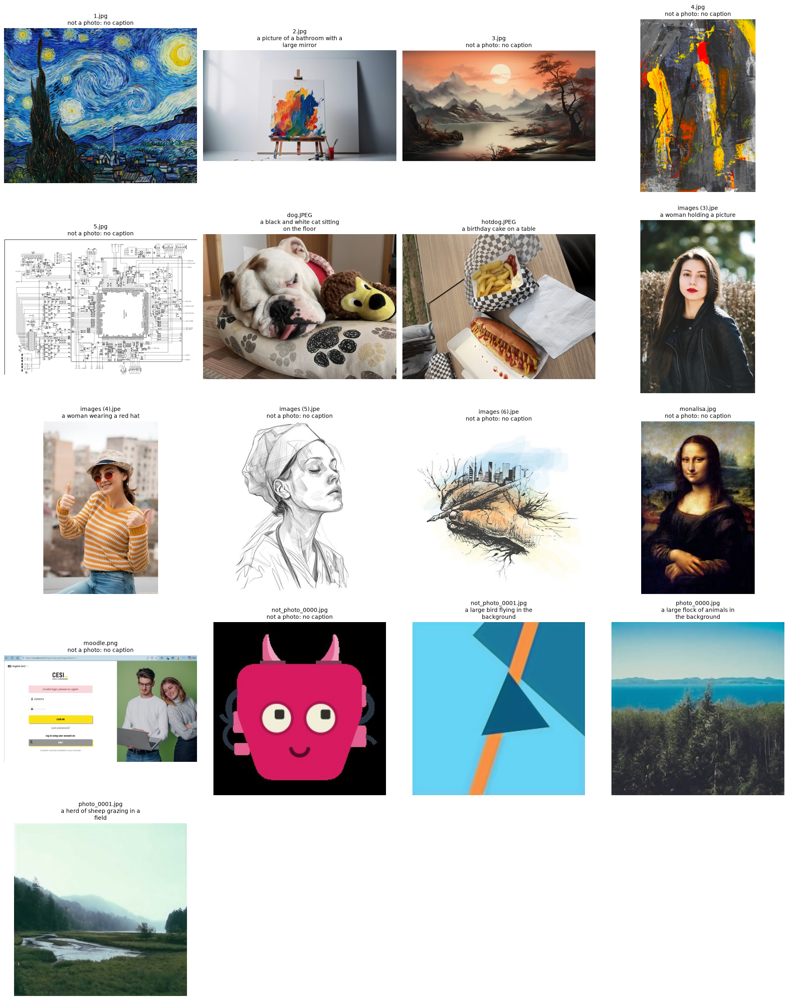

In [28]:
input_paths = sorted(p for p in glob(os.path.join(INPUT_DIR, "*"))
                     if p.lower().endswith((".jpg", ".jpeg", ".jpe", ".png")))
results = [run_workflow(p) for p in input_paths]

for r in results:
    if r["photo"]:
        print(f"{r['file']:<16} photo ({r['p_photo']:.0%})       -> {r['caption']}")
    else:
        print(f"{r['file']:<16} not a photo ({1 - r['p_photo']:.0%}) -> set aside")

cols = 4
rows = math.ceil(len(results) / cols)
plt.figure(figsize=(5 * cols, 5 * rows))
for i, (path, r) in enumerate(zip(input_paths, results)):
    plt.subplot(rows, cols, i + 1)
    plt.imshow(Image.open(r["output"] if r["photo"] else path).convert("RGB"))
    title = "\n".join(textwrap.wrap(r["caption"], 30)) if r["photo"] else "not a photo: no caption"
    plt.title(f"{r['file']}\n{title}", fontsize=10)
    plt.axis("off")
plt.tight_layout()
plt.show()